# Bike demand forecasting, pricing and capacity planning
Bike store: two-week demand forecasting (OLS), price-based choice model
(multinomial logistic regression), and a two-stage capacity / price / quantity
decision evaluated over a test year (rolling backtest).

**Information-set convention used throughout.** Period *t* covers the 14 days
starting `period_start[t]`. A decision taken at the start of period *t − k* can
only use demand of periods that have fully ended (≤ *t − k − 1*) and
transactions dated before that day. Every model used for a decision is
re-estimated on exactly that information (expanding window).

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

DATA = "sales_transactions.csv"
PRODUCTS = ["Comfort Mountain", "Tough Track", "Ultimate Mountain"]
SHORT = ["CM", "TT", "UM"]
PRICE_COLS = ["Price_Comfort_Mountain", "Price_Tough_Track", "Price_Ultimate_Mountain"]
HORIZONS = [1, 2, 3, 4]       # Q1 forecast horizons (two-week periods)
SEASON = 26                   # two-week periods per year
N_TEST = 26                   # test year: last 26 periods

df = pd.read_csv(DATA, parse_dates=["order_date", "delivery_date"])
start = df["order_date"].min()
df["period"] = (df["order_date"] - start).dt.days // 14
n_periods = int(df["period"].max()) + 1
print(df.shape, "transactions;", df["quantity"].sum(), "bikes;", n_periods, "two-week periods")
df.head()

(1682, 8) transactions; 2051 bikes; 130 two-week periods


,Product,quantity,order_date,delivery_date,Price_Comfort_Mountain,Price_Tough_Track,Price_Ultimate_Mountain,period
0,Tough Track,1,2021-02-07,2021-02-20,4939,1680,480,0
1,Ultimate Mountain,2,2021-02-08,2021-02-19,4870,2102,649,0
2,Ultimate Mountain,1,2021-02-11,2021-02-20,4564,2029,525,0
3,Ultimate Mountain,1,2021-02-15,2021-02-23,4075,2263,240,0
4,Comfort Mountain,1,2021-02-20,2021-02-28,3360,1800,649,0


## Question 1 – Two-week aggregation and OLS forecasts for horizons 1–4

Demand = number of bikes (`quantity`) ordered in the period, summed over the
three products. The data span exactly 1,820 days (2021-02-07 to 2026-01-31),
i.e. 130 complete two-week periods.

In [2]:
biweekly = (df.groupby("period")["quantity"].sum()
              .reindex(range(n_periods), fill_value=0).to_frame("demand"))
biweekly = biweekly.join(df.pivot_table(index="period", columns="Product", values="quantity",
                                        aggfunc="sum", fill_value=0)
                           .reindex(range(n_periods), fill_value=0))
biweekly["period_start"] = start + pd.to_timedelta(biweekly.index * 14, unit="D")
y = biweekly["demand"].astype(float)
period_start = biweekly["period_start"]

test_idx = list(range(n_periods - N_TEST, n_periods))                 # 104..129
valid_idx = list(range(78, test_idx[0] - 4))  # 78..99: complete before the first test decision
print("validation:", period_start[valid_idx[0]].date(), "to", (period_start[valid_idx[-1]] + pd.Timedelta(days=13)).date())
print("test:      ", period_start[test_idx[0]].date(), "to", (period_start[test_idx[-1]] + pd.Timedelta(days=13)).date())
biweekly.head()

validation: 2024-02-04 to 2024-12-07
test:       2025-02-02 to 2026-01-31


,demand,Comfort Mountain,Tough Track,Ultimate Mountain,period_start
period,,,,,
0,6,1,1,4,2021-02-07
1,4,3,0,1,2021-02-21
2,6,3,1,2,2021-03-07
3,13,7,5,1,2021-03-21
4,8,4,2,2,2021-04-04


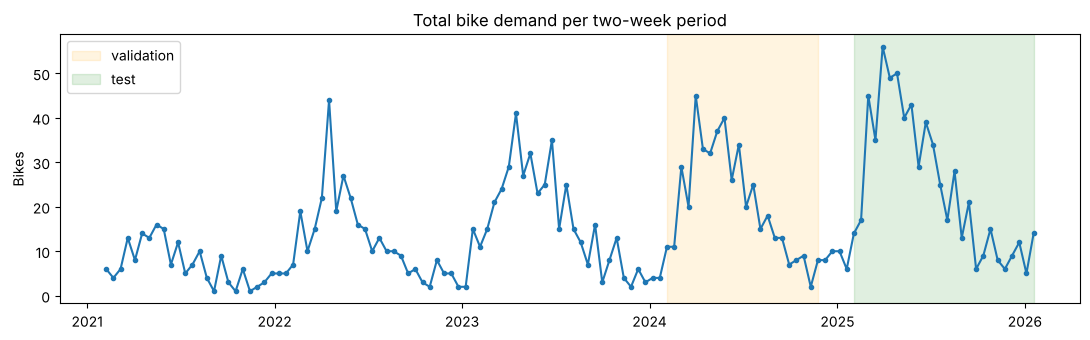

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(period_start, y, marker=".")
ax.axvspan(period_start[valid_idx[0]], period_start[valid_idx[-1]], color="orange", alpha=0.12, label="validation")
ax.axvspan(period_start[test_idx[0]], period_start[test_idx[-1]], color="green", alpha=0.12, label="test")
ax.set_title("Total bike demand per two-week period")
ax.set_ylabel("Bikes")
ax.legend()
plt.tight_layout()
plt.savefig("fig_q1_demand.png", dpi=150)
plt.show()

**Candidate models.** For horizon *h* (forecast issued once period *t − h* has
ended) every candidate may only use lags ≥ *h*:

| name | regressors |
|---|---|
| `base` | trend, annual sin/cos, lag *h*, lag *h+1*, lag 26 |
| `fourier2` | trend, 2 annual harmonics, lag 26 |
| `fourier2_lags` | trend, 2 annual harmonics, lag *h*, lag *h+1*, lag 26 |
| `trend_lag26` | trend, lag 26 |

**Rolling-origin evaluation.** Each forecast of period *t* at horizon *h* uses a
model estimated only on target periods ≤ *t − h*, so no parameter uses data
from after the forecast origin. The model specification is chosen on periods
78–99, the last period completed before the earliest test-year decision (the
capacity reservation for period 104 at the start of period 100), and is then
frozen; only its parameters are updated. Periods 104–129 are a rolling backtest
over the historical test interval. (Earlier drafts of this project looked at
test-interval results, so the backtest is not a fully untouched hold-out.)

In [4]:
SPECS = {
    "base":          ["trend", "s1", "c1", "lag_h", "lag_h1", "lag_26"],
    "fourier2":      ["trend", "s1", "c1", "s2", "c2", "lag_26"],
    "fourier2_lags": ["trend", "s1", "c1", "s2", "c2", "lag_h", "lag_h1", "lag_26"],
    "trend_lag26":   ["trend", "lag_26"],
}

def make_features(h, spec):
    t = y.index.to_numpy()
    X = pd.DataFrame(index=y.index)
    X["trend"] = t
    for k in (1, 2):
        X[f"s{k}"] = np.sin(2 * np.pi * k * t / SEASON)
        X[f"c{k}"] = np.cos(2 * np.pi * k * t / SEASON)
    X["lag_h"] = y.shift(h)
    X["lag_h1"] = y.shift(h + 1)
    X["lag_26"] = y.shift(SEASON)
    return sm.add_constant(X[SPECS[spec]])

FEATURES = {(h, s): make_features(h, s) for h in range(1, 7) for s in SPECS}

def fit_ols(h, spec, last_target):
    """OLS for horizon h estimated on target periods <= last_target."""
    X = FEATURES[(h, spec)]
    rows = X.index[(X.index <= last_target) & X.notna().all(axis=1)]
    return sm.OLS(y[rows], X.loc[rows]).fit()

def rolling_forecast(h, spec, t):
    """Forecast of period t issued after period t-h has ended."""
    model = fit_ols(h, spec, t - h)
    return float(model.predict(FEATURES[(h, spec)].loc[[t]]).iloc[0])

def evaluate(spec, targets, h):
    f = np.array([rolling_forecast(h, spec, t) for t in targets])
    return y[targets].to_numpy() - f, f

In [5]:
rows = []
for spec in SPECS:
    for h in HORIZONS:
        err, _ = evaluate(spec, valid_idx, h)
        rows.append({"model": spec, "h": h, "valid MAE": np.abs(err).mean()})
valid_err = y[valid_idx].to_numpy() - y.shift(SEASON)[valid_idx].to_numpy()
validation = pd.DataFrame(rows).pivot(index="model", columns="h", values="valid MAE")
validation["mean MAE"] = validation.mean(axis=1)
validation.loc["seasonal naive (lag 26)"] = [np.abs(valid_err).mean()] * 4 + [np.abs(valid_err).mean()]
SPEC = validation.drop("seasonal naive (lag 26)")["mean MAE"].idxmin()
print("Selected on validation:", SPEC)
validation.round(3)

Selected on validation: base


h,1,2,3,4,mean MAE
model,,,,,
base,3.880,3.887,4.201,3.879,3.962
fourier2,4.384,4.111,4.313,4.283,4.272
fourier2_lags,3.924,4.139,4.265,4.141,4.117
trend_lag26,5.151,4.877,4.994,4.946,4.992
seasonal naive (lag 26),4.773,4.773,4.773,4.773,4.773


In [6]:
naive_err = y[test_idx].to_numpy() - y.shift(SEASON)[test_idx].to_numpy()
naive_mae = np.abs(naive_err).mean()
q1_rows, test_fc = [], {}
for h in HORIZONS:
    err, f = evaluate(SPEC, test_idx, h)
    test_fc[h] = f
    full = fit_ols(h, SPEC, test_idx[0] - 1)  # descriptive fit on all pre-test data
    mae = np.abs(err).mean()
    q1_rows.append({
        "horizon h": h,
        "train R2 (pre-test fit)": full.rsquared,
        "test MAE": mae,
        "test RMSE": np.sqrt((err ** 2).mean()),
        "test MAPE %": (np.abs(err) / y[test_idx].to_numpy()).mean() * 100,
        "seasonal-naive MAE": naive_mae,
        "MAE improvement vs naive %": (1 - mae / naive_mae) * 100,
    })
q1_summary = pd.DataFrame(q1_rows).round(3)
q1_summary

,horizon h,train R2 (pre-test fit),test MAE,test RMSE,test MAPE %,seasonal-naive MAE,MAE improvement vs naive %
0,1,0.788,5.489,6.877,30.787,6.346,13.511
1,2,0.786,5.484,6.990,30.805,6.346,13.581
2,3,0.783,5.562,7.359,30.270,6.346,12.355
3,4,0.789,5.444,7.016,29.899,6.346,14.212


In [7]:
for h in HORIZONS:
    print(f"\n===== Horizon h = {h} (estimated on periods up to {test_idx[0] - 1}) =====")
    print(fit_ols(h, SPEC, test_idx[0] - 1).summary().tables[1])


===== Horizon h = 1 (estimated on periods up to 103) =====
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.5034      2.208      3.398      0.001       3.101      11.906
trend          0.0412      0.037      1.114      0.269      -0.033       0.115
s1             8.8000      2.239      3.931      0.000       4.336      13.264
c1            -0.4605      1.265     -0.364      0.717      -2.984       2.063
lag_h         -0.0973      0.110     -0.887      0.378      -0.316       0.121
lag_h1         0.1257      0.112      1.127      0.263      -0.097       0.348
lag_26         0.4384      0.115      3.803      0.000       0.209       0.668

===== Horizon h = 2 (estimated on periods up to 103) =====
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      

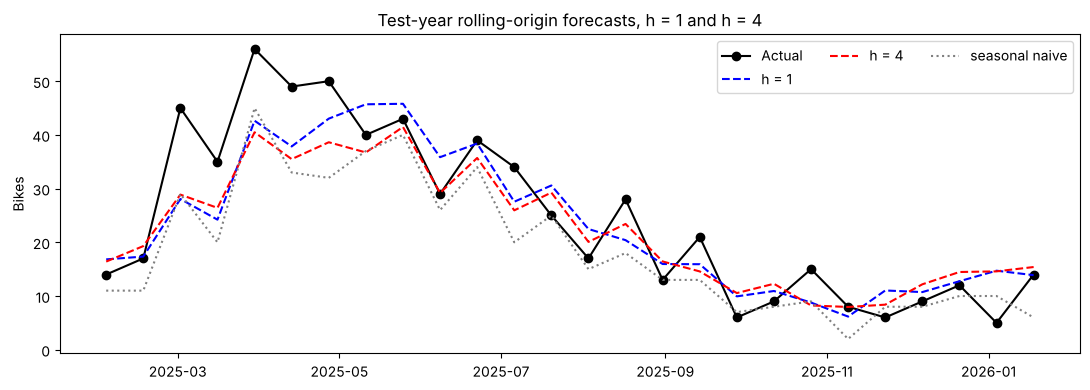

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(period_start[test_idx], y[test_idx], "k-o", label="Actual")
for h, style in [(1, "b--"), (4, "r--")]:
    ax.plot(period_start[test_idx], test_fc[h], style, label=f"h = {h}")
ax.plot(period_start[test_idx], y.shift(SEASON)[test_idx], ":", color="grey", label="seasonal naive")
ax.set_title("Test-year rolling-origin forecasts, h = 1 and h = 4")
ax.set_ylabel("Bikes")
ax.legend(ncol=3)
plt.tight_layout()
plt.savefig("fig_q1_forecasts.png", dpi=150)
plt.show()

## Question 2 – Logistic regression for bike choice

Each transaction is one choice among the three bikes, with the three prices
observed at that time. A multinomial logit (base: Comfort Mountain, prices in
$100s) is fitted on all 1,682 transactions. Q2 does not ask for a train/test
split, so the full-sample fit answers Q2 and is descriptive only. The same model
fitted only on transactions before the first Q3 decision (8 Dec 2024) is shown
next to it; all Q3 decisions use logit models estimated only from information
available before each decision.

In [9]:
CHOICE_CODE = {p: i for i, p in enumerate(PRODUCTS)}

def fit_choice_model(data, weight_by_quantity=False):
    if weight_by_quantity:  # integer frequency weights via row replication (point estimates only)
        data = data.loc[data.index.repeat(data["quantity"])]
    X = sm.add_constant(data[PRICE_COLS] / 100)
    return sm.MNLogit(data["Product"].map(CHOICE_CODE), X).fit(disp=False)

def choice_probs(model, prices):
    prices = np.atleast_2d(np.asarray(prices, dtype=float))
    X = np.column_stack([np.ones(len(prices)), prices / 100])
    return np.asarray(model.predict(X))

logit_full = fit_choice_model(df)
print(logit_full.summary())
pred_class = np.asarray(logit_full.predict()).argmax(axis=1)
print(f"In-sample accuracy: {(pred_class == df['Product'].map(CHOICE_CODE).values).mean():.3f}"
      f"  (majority-class baseline: {df['Product'].value_counts(normalize=True).max():.3f})")
print(f"McFadden pseudo R2: {logit_full.prsquared:.3f}")

                          MNLogit Regression Results                          
Dep. Variable:                Product   No. Observations:                 1682
Model:                        MNLogit   Df Residuals:                     1674
Method:                           MLE   Df Model:                            6
Date:                Tue, 13 Oct 2026   Pseudo R-squ.:                  0.7292
Time:                        06:40:53   Log-Likelihood:                -500.17
converged:                       True   LL-Null:                       -1847.3
Covariance Type:            nonrobust   LLR p-value:                     0.000
              Product=1       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       6.9167      1.363      5.073      0.000       4.244       9.589
Price_Comfort_Mountain      0.6734      0.044     15.206      0.000       0.587       0.760


In [10]:
q2_prices = np.array([4200, 1950, 500])
q2_probs = choice_probs(logit_full, q2_prices)[0]
TRAIN_END = test_idx[0] - 4                 # first Q3 decision: start of period 100 (8 Dec 2024)
tx_train = df[df["order_date"] < period_start[TRAIN_END]]
logit_train = fit_choice_model(tx_train)
print(f"Training-data logit: {len(tx_train)} transactions before {period_start[TRAIN_END].date()}, "
      f"McFadden pseudo R2 = {logit_train.prsquared:.3f}")
print(logit_train.summary())
q2_table = pd.DataFrame({"Price ($)": q2_prices,
                         "Choice probability (all data)": q2_probs.round(4),
                         "Choice probability (training data)": choice_probs(logit_train, q2_prices)[0].round(4)},
                        index=PRODUCTS)
q2_table

Training-data logit: 1129 transactions before 2024-12-08, McFadden pseudo R2 = 0.730
                          MNLogit Regression Results                          
Dep. Variable:                Product   No. Observations:                 1129
Model:                        MNLogit   Df Residuals:                     1121
Method:                           MLE   Df Model:                            6
Date:                Tue, 13 Oct 2026   Pseudo R-squ.:                  0.7305
Time:                        06:40:53   Log-Likelihood:                -333.98
converged:                       True   LL-Null:                       -1239.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
              Product=1       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       8.6561      1.678      5.158      0.000       5.367      11.945
Price_C

,Price ($),Choice probability (all data),Choice probability (training data)
Comfort Mountain,4200,0.1820,0.2162
Tough Track,1950,0.2989,0.2449
Ultimate Mountain,500,0.5191,0.5390


**Unit of analysis.** The logit models *transactions*, while the OLS model
forecasts *bikes* (1,682 transactions, 2,051 bikes; 286 transactions contain
more than one bike). Using D̂ × P(choice) assumes transaction shares equal bike
shares. The checks below compare the two shares and refit the logit with the
log-likelihood weighted by `quantity`. Only point predictions are compared:
replicated rows are not independent choices, so the default standard errors of
the weighted fit are not used for inference.

In [11]:
units = pd.DataFrame({
    "transactions": df["Product"].value_counts(),
    "bikes": df.groupby("Product")["quantity"].sum(),
    "avg bikes per transaction": df.groupby("Product")["quantity"].mean().round(3),
}).loc[PRODUCTS]
units["transaction share %"] = (units["transactions"] / units["transactions"].sum() * 100).round(2)
units["bike share %"] = (units["bikes"] / units["bikes"].sum() * 100).round(2)
units["difference (pp)"] = (units["bike share %"] - units["transaction share %"]).round(2)
logit_full_w = fit_choice_model(df, weight_by_quantity=True)
units["P at Q2 prices (transaction model) %"] = (q2_probs * 100).round(2)
units["P at Q2 prices (quantity-weighted) %"] = (choice_probs(logit_full_w, q2_prices)[0] * 100).round(2)
units

,transactions,bikes,avg bikes per transaction,transaction share %,bike share %,difference (pp),P at Q2 prices (transaction model) %,P at Q2 prices (quantity-weighted) %
Product,,,,,,,,
Comfort Mountain,540,662,1.226,32.10,32.28,0.18,18.20,19.60
Tough Track,571,707,1.238,33.95,34.47,0.52,29.89,29.09
Ultimate Mountain,571,682,1.194,33.95,33.25,-0.70,51.91,51.31


**Rolling out-of-sample check.** For each test-interval period *t*, the logit is
re-estimated on transactions dated before the pricing decision (start of
*t − 1*) and used to predict the choices actually made in period *t* at the
prices actually charged. The benchmark predicts every choice with the
historical product shares available at the same date. This measures predictive
ability under historical prices, not the causal effect of changing prices.

In [12]:
oos = {"correct": [], "logloss": [], "share_logloss": []}
for t in test_idx:
    tx_t = df[df["period"] == t]
    if tx_t.empty:
        continue
    past = df[df["order_date"] < period_start[t - 1]]
    probs_t = choice_probs(fit_choice_model(past), tx_t[PRICE_COLS].values)
    chosen = tx_t["Product"].map(CHOICE_CODE).values
    shares = past["Product"].value_counts(normalize=True).reindex(PRODUCTS).values
    oos["correct"] += list(probs_t.argmax(axis=1) == chosen)
    oos["logloss"] += list(-np.log(probs_t[np.arange(len(chosen)), chosen]))
    oos["share_logloss"] += list(-np.log(shares[chosen]))
q2_oos = pd.Series({
    "test-interval transactions": len(oos["correct"]),
    "out-of-sample accuracy": np.mean(oos["correct"]),
    "out-of-sample log loss (logit)": np.mean(oos["logloss"]),
    "log loss of historical-share benchmark": np.mean(oos["share_logloss"]),
})
q2_oos.round(3)

test-interval transactions                528.000
out-of-sample accuracy                      0.879
out-of-sample log loss (logit)              0.307
log loss of historical-share benchmark      1.100
dtype: float64

## Question 3 – Two-stage capacity, price and quantity decisions

### Timeline and information sets
Four two-week periods (56 days) approximate "two months". A decision at the
start of period *t − k* can use demand of periods ≤ *t − k − 1* and
transactions dated before that day.

| stage | when | latest complete demand | demand forecast |
|---|---|---|---|
| 1. reserve shared capacity *K* | start of *t − 4* | *y(t − 5)* | OLS with lags ≥ 5 (D̂₅) |
| 2. set prices *p* and integer order quantities *q* | start of *t − 1* | *y(t − 2)* | OLS with lags ≥ 2 (D̂₂) |

Every forecast, forecast-error sample, logit model and price range used for a
decision is computed only from information available on that decision date.

### Contract and costs (assumptions for this experiment, not supplier quotes)
* Unit purchase cost cⱼ = 65% of the Q2 reference price ($2,730 / $1,267.50 /
  $325), fixed regardless of the retail price chosen.
* Reserving *K* units costs a deposit of $100 per unit, paid at stage 1.
  Each bike ordered at stage 2 uses one unit and the $100 is credited against
  its purchase cost; unused deposits are forfeited. Capacity is valid only for
  its own two-week period.
* Unsold bikes are disposed of at the end of the period at a net salvage value
  sⱼ = 50% of cost (scenario value); there is no carry-over.

Profit of one period:
Π = Σⱼ [ pⱼ·min(qⱼ, Dⱼ) + sⱼ·(qⱼ − Dⱼ)⁺ − (cⱼ − 100)·qⱼ ] − 100·K,  with Σⱼ qⱼ ≤ K.

### Demand uncertainty
* **Total demand.** D = round(max(D̂₂ + e, 0)), where *e* is drawn from the
  **rolling-origin** lag-2 forecast errors of earlier periods (each error comes
  from a model estimated only on data before its own forecast origin), not
  from in-sample residuals.
* **Forecast update between the stages.** At stage 1, D̂₂ is not yet known. It is
  simulated as D̂₅ + u, with *u* the historical gap between the rolling lag-2 and
  lag-5 forecasts of the same period. Then D = D̂₅ + u + e, so the 8-week error
  (u + e) and the 2-week error (e) are correlated through *e*; *u* and *e*
  are treated as independent (checked below).
* **Split across bikes.** Given D, (D_CM, D_TT, D_UM) | D ~ Multinomial(D; P_CM,
  P_TT, P_UM) with the logit probabilities, so the three demands always add up
  to D. Each bike's marginal demand is Binomial(D, Pⱼ(p)); the expected profit
  is a sum over bikes, so only these marginals are needed to compute the
  expected marginal order values. This assumes that transaction choice shares
  apply to individual bikes and that bikes choose independently. In the data a
  multi-bike transaction always contains one model, so this understates the
  variance of each bike's demand (E[q²]/E[q] = 1.44 bikes per transaction).

### Optimization
* **Stage 2.** For fixed prices, the expected value of the (k)-th unit of bike *j*
  is (pⱼ − sⱼ)·P(Dⱼ ≥ k) + sⱼ − (cⱼ − 100), which decreases in *k*. Units are
  added one at a time to the bike with the highest positive marginal value until
  *K* is used or no marginal value is positive; this gives the optimal integer
  quantities for those prices. Prices (whole dollars, between the 5th
  percentile and the cap percentile of past prices) are searched on a
  coarse-then-fine grid: a numerical candidate within the search range, not a
  proof of global optimality.
* **Stage 1.** K* = argmax_K { E[V₂(K) | info at t − 4] − 100·K }, where V₂ is the
  stage-2 optimal expected value: for each simulated D̂₂ the prices and
  quantities are re-optimized against the remaining uncertainty *e*, never
  against a realized demand.
  Stage 1 searches 11 whole-dollar prices per bike; the reported *K* is optimal
  on that discrete grid (a grid-convergence check follows the results).
* **Approximation.** The capacity stage simulates only the update of the demand
  forecast; it keeps the logit model, price bounds and error distribution at
  their values on the reservation date. The pricing stage re-estimates them
  with the newer data. *K* is therefore optimal for this approximate model,
  not for a full dynamic model of future learning.

In [13]:
from scipy.special import betainc

REF_PRICE = np.array([4200.0, 1950.0, 500.0])
BASE = dict(cost_ratio=0.65, deposit=100.0, salvage_ratio=0.50, cap_q=0.95,
            logit="transaction", fixed_prices=None)
H_CAP, H_PRICE = 5, 2
K_MAX, D_MAX = 100, 120
MIN_FIT_ROWS = 20
N_PGRID = 501                                   # grid of choice probabilities for lookup

# Rolling-origin forecasts of every period at lags 2 and 5 (model fit on data <= s - h)
def rolling_or_nan(h, s):
    if s - h - 25 < MIN_FIT_ROWS:
        return np.nan
    return rolling_forecast(h, SPEC, s)

FC = {h: pd.Series([rolling_or_nan(h, s) for s in range(n_periods)]) for h in (H_PRICE, H_CAP)}

# Fixed-parameter variant (comparison only): OLS estimated once on target periods
# before the first decision; test-period demand enters only as observed lags.
FC_FIXED = {}
for h in (H_PRICE, H_CAP):
    m = fit_ols(h, SPEC, TRAIN_END - 1)
    FC_FIXED[h] = pd.Series(np.nan, index=range(n_periods))
    FC_FIXED[h][test_idx] = m.predict(FEATURES[(h, SPEC)].loc[test_idx]).to_numpy()

def errors_until(last, parity=None):
    """Rolling lag-2 errors e and forecast updates u of periods <= last."""
    s = np.array([i for i in range(last + 1) if np.isfinite(FC[2][i]) and np.isfinite(FC[5][i])])
    if parity is not None:
        s = s[s % 2 == parity]
    e = y[s].to_numpy() - FC[2][s].to_numpy()
    u = FC[2][s].to_numpy() - FC[5][s].to_numpy()
    return e, u

# Error samples available at the first decisions of the test year
for label, last in [("first capacity decision (8 Dec 2024)", test_idx[0] - 5),
                    ("first pricing decision (19 Jan 2025)", test_idx[0] - 2)]:
    e_pre, u_pre = errors_until(last)
    print(f"{label}: periods <= {last}, n = {len(e_pre)}, mean lag-2 error = {e_pre.mean():.2f}, "
          f"sd = {e_pre.std(ddof=1):.2f}, corr(u, e) = {np.corrcoef(u_pre, e_pre)[0, 1]:.3f}")

# P(Binomial(d, p) >= k) for k = 1..K_MAX, d = 0..D_MAX, p on a fine grid (computed once)
P_AXIS = np.linspace(0, 1, N_PGRID)
_k = np.arange(1, K_MAX + 1)[None, :, None]
_d = np.arange(D_MAX + 1)[None, None, :]
_p = P_AXIS[:, None, None]
with np.errstate(all="ignore"):
    SF = np.where(_k <= _d, betainc(_k, np.maximum(_d - _k + 1, 1), _p), 0.0)   # (P, K, D)

def demand_pmf(centres, e):
    """pmf of total demand for each centre (D̂), using error sample e -> (n_centres, D_MAX+1)."""
    d = np.clip(np.round(np.maximum(np.asarray(centres)[:, None] + e[None, :], 0)), 0, D_MAX).astype(int)
    pmf = np.zeros((len(d), D_MAX + 1))
    for i, row in enumerate(d):
        pmf[i] = np.bincount(row, minlength=D_MAX + 1) / len(row)
    return pmf

def tail_table(pmf):
    """T[c, p, k] = P(D_j >= k) when each bike picks j with probability P_AXIS[p]."""
    return (pmf @ SF.reshape(-1, D_MAX + 1).T).reshape(len(pmf), N_PGRID, K_MAX)

def tails_at(T, probs):
    """Interpolate tail table at choice probabilities probs (G,3) -> (C, G, 3, K)."""
    x = probs * (N_PGRID - 1)
    i0 = np.clip(np.floor(x).astype(int), 0, N_PGRID - 2)
    w = (x - i0)[None, :, :, None]
    return T[:, i0, :] * (1 - w) + T[:, i0 + 1, :] * w

def unit_costs(cfg):
    c = cfg["cost_ratio"] * REF_PRICE
    return c, cfg["salvage_ratio"] * c

def marginals(prices, tails, cfg):
    """Expected value of each additional unit -> (C, G, 3, K)."""
    c, s = unit_costs(cfg)
    return ((prices - s)[None, :, :, None] * tails
            + (s - (c - cfg["deposit"]))[None, None, :, None])

def value_curve(marg):
    """Best value using at most K units, K = 0..K_MAX -> (C, G, K_MAX+1)."""
    C, G = marg.shape[:2]
    m = -np.sort(-marg.reshape(C, G, -1), axis=2)[:, :, :K_MAX]
    return np.concatenate([np.zeros((C, G, 1)), np.cumsum(np.maximum(m, 0), axis=2)], axis=2)

def price_grid(lo, hi, n):
    # whole-dollar prices that stay inside the continuous bounds
    g = [np.unique(np.round(np.linspace(np.ceil(l), np.floor(h), n))) for l, h in zip(lo, hi)]
    return np.array(np.meshgrid(*g)).reshape(3, -1).T

first capacity decision (8 Dec 2024): periods <= 99, n = 50, mean lag-2 error = -0.24, sd = 6.00, corr(u, e) = 0.040
first pricing decision (19 Jan 2025): periods <= 102, n = 53, mean lag-2 error = -0.12, sd = 5.85, corr(u, e) = 0.040


In [14]:
# Information available at each decision date (cached: logits, price ranges, error samples)
_logit_cache = {}
def info_period(period, cfg):
    # fixed-parameter variant: every decision uses information up to the first decision only
    return min(period, TRAIN_END) if cfg.get("fixed_params") else period

def logit_at(period, kind):
    key = (period, kind)
    if key not in _logit_cache:
        tx = df[df["order_date"] < period_start[period]]
        _logit_cache[key] = fit_choice_model(tx, weight_by_quantity=(kind == "weighted"))
    return _logit_cache[key]

def bounds_at(period, cap_q):
    tx = df[df["order_date"] < period_start[period]]
    return tx[PRICE_COLS].quantile(0.05).values, tx[PRICE_COLS].quantile(cap_q).values

_table_cache = {}
def tables_for(t, parity=None, fixed=False):
    """Tail tables at reservation (one per simulated D̂2) and at pricing (actual D̂2)."""
    key = (t, parity, fixed)
    if key not in _table_cache:
        last = TRAIN_END - 1 if fixed else None
        e_res, u_res = errors_until(t - 5 if last is None else last, parity)
        e_pr, _ = errors_until(t - 2 if last is None else last, parity)
        fc = FC_FIXED if fixed else FC
        _table_cache[key] = dict(
            d5=fc[5][t], d2=fc[2][t],
            T_res=tail_table(demand_pmf(FC[5][t] + u_res, e_res)),
            T_pr=tail_table(demand_pmf([FC[2][t]], e_pr)),
        )
    return _table_cache[key]

In [15]:
def stage1(t, cfg, parity=None, grid_n=11):
    tb = tables_for(t, parity, cfg.get("fixed_params", False))
    logit = logit_at(info_period(t - 4, cfg), cfg["logit"])
    lo, hi = bounds_at(info_period(t - 4, cfg), cfg["cap_q"])
    P = np.atleast_2d(cfg["fixed_prices"]) if cfg["fixed_prices"] is not None else price_grid(lo, hi, grid_n)
    best = None                                         # (U, K+1): best prices per simulated D̂2
    for chunk in np.array_split(P, max(1, len(P) // 150)):
        V = value_curve(marginals(chunk, tails_at(tb["T_res"], choice_probs(logit, chunk)), cfg)).max(axis=1)
        best = V if best is None else np.maximum(best, V)
    EV = best.mean(axis=0)
    profit = EV - cfg["deposit"] * np.arange(K_MAX + 1)
    return int(np.argmax(profit)), EV

def stage2_search(K, P, T, logit, cfg):
    marg = marginals(P, tails_at(T, choice_probs(logit, P)), cfg)[0]       # (G, 3, K_MAX)
    flat = marg.reshape(len(P), -1)
    order = np.argsort(-flat, axis=1)
    top = np.take_along_axis(flat, order[:, :K], axis=1)
    value = np.maximum(top, 0).sum(axis=1)
    i = int(np.argmax(value))
    used = order[i, :K][top[i] > 0]
    q = np.bincount(used // K_MAX, minlength=3)
    # capacity binds if all K units are used and one more unit would still add value
    binding = bool(q.sum() == K and K < flat.shape[1] and flat[i, order[i, K]] > 0)
    return value[i], P[i], q, binding

def stage2(t, K, cfg, parity=None):
    tb = tables_for(t, parity, cfg.get("fixed_params", False))
    logit = logit_at(info_period(t - 1, cfg), cfg["logit"])
    lo, hi = bounds_at(info_period(t - 1, cfg), cfg["cap_q"])
    if cfg["fixed_prices"] is not None:
        return stage2_search(K, np.atleast_2d(cfg["fixed_prices"]), tb["T_pr"], logit, cfg) + ((lo, hi),)
    v, p, q, _ = stage2_search(K, price_grid(lo, hi, 13), tb["T_pr"], logit, cfg)
    step = (hi - lo) / 12
    v, p, q, b = stage2_search(K, price_grid(np.maximum(p - step, lo), np.minimum(p + step, hi), 9),
                               tb["T_pr"], logit, cfg)
    return v, p, q, b, (lo, hi)

def evaluate_plan(t, K, p, q, cfg, parity=None, logit_kind=None):
    """Expected outcome of fixed (K, p, q) under the stage-2 demand distribution."""
    tb = tables_for(t, parity, cfg.get("fixed_params", False))
    logit = logit_at(info_period(t - 1, cfg), logit_kind or cfg["logit"])
    c, s = unit_costs(cfg)
    tails = tails_at(tb["T_pr"], choice_probs(logit, p))[0, 0]             # (3, K_MAX)
    sales = np.array([tails[j, :q[j]].sum() for j in range(3)])           # E[min(q, D)]
    unsold = q - sales
    out = dict(exp_sales=sales.sum(), exp_unsold=unsold.sum(),
               revenue=float(p @ sales), salvage=float(s @ unsold),
               purchase_cost=float(c @ q), forfeited_deposit=cfg["deposit"] * (K - q.sum()))
    out["profit"] = out["revenue"] + out["salvage"] - out["purchase_cost"] - out["forfeited_deposit"]
    return out

def run_policy(cfg, parity=None, label=""):
    rows = []
    for t in test_idx:
        K, _ = stage1(t, cfg, parity)
        v, p, q, binding, (lo, hi) = stage2(t, K, cfg, parity)
        if cfg["fixed_prices"] is None:
            assert np.all(p >= lo) and np.all(p <= hi), "price outside allowed range"
        ev = evaluate_plan(t, K, p, q, cfg, parity)
        assert abs(ev["profit"] - (v - cfg["deposit"] * K)) < 1e-6 * max(1, abs(v))
        rows.append({"period": t, "period_start": period_start[t].date(),
                     "forecast_lag5": tables_for(t, parity, cfg.get("fixed_params", False))["d5"],
                     "capacity_K": K,
                     "forecast_lag2": tables_for(t, parity, cfg.get("fixed_params", False))["d2"],
                     **{f"price_{s_}": p[j] for j, s_ in enumerate(SHORT)},
                     **{f"qty_{s_}": int(q[j]) for j, s_ in enumerate(SHORT)},
                     "unused_capacity": K - int(q.sum()),
                     "capacity_binding": binding,
                     **{f"at_cap_{s_}": bool(p[j] >= np.floor(hi[j])) for j, s_ in enumerate(SHORT)},
                     **ev, "historical_demand": int(y[t])})
    return pd.DataFrame(rows)

def summarize(plan, label):
    return {
        "scenario": label,
        "capacity K": plan["capacity_K"].sum(),
        **{f"qty {s_}": plan[f"qty_{s_}"].sum() for s_ in SHORT},
        "unused capacity": plan["unused_capacity"].sum(),
        "exp. sales": plan["exp_sales"].sum(),
        "exp. unsold": plan["exp_unsold"].sum(),
        "binding periods %": 100 * plan["capacity_binding"].mean(),
        **{f"{s_} at cap (periods)": int(plan[f"at_cap_{s_}"].sum()) for s_ in SHORT},
        "avg price CM": plan["price_CM"].mean(),
        "exp. revenue": plan["revenue"].sum(),
        "exp. profit": plan["profit"].sum(),
    }

### Accuracy of the forecasts behind the two decisions
Q1 reports horizons 1–4; the capacity decision uses the lag-5 forecast and the
pricing decision the lag-2 forecast. Errors are actual − forecast over the test
interval (rolling origin), next to the mean error that was observable before
the first test decision.

In [16]:
fc_rows = []
for h, use in [(H_CAP, "capacity (stage 1)"), (H_PRICE, "pricing (stage 2)")]:
    err_test = y[test_idx].to_numpy() - FC[h][test_idx].to_numpy()
    first_decision = test_idx[0] - (4 if h == H_CAP else 1)              # start of t-4 or t-1
    pre = [i for i in range(first_decision)                                # complete before it, same
           if np.isfinite(FC[2][i]) and np.isfinite(FC[5][i])]              # sample as the optimizer
    err_pre = y[pre].to_numpy() - FC[h][pre].to_numpy()
    fc_rows.append({"forecast": f"lag-{h}", "used for": use,
                    "test MAE": np.abs(err_test).mean(), "test RMSE": np.sqrt((err_test ** 2).mean()),
                    "test mean error": err_test.mean(),
                    "mean error known at first decision": err_pre.mean(),
                    "pre-decision error sample size": len(pre)})
forecast_eval = pd.DataFrame(fc_rows).set_index("forecast")
forecast_eval.round(2)

,used for,test MAE,test RMSE,test mean error,mean error known at first decision,pre-decision error sample size
forecast,,,,,,
lag-5,capacity (stage 1),5.76,7.22,2.54,-0.74,50
lag-2,pricing (stage 2),5.48,6.99,1.37,-0.12,53


Both forecasts under-predicted test-interval demand on average, which raises the
risk of too little capacity, especially in the spring peak. The bias observable
before the first decision had the opposite sign, so a bias correction estimated
at decision time would not have helped here; adding back the test-interval bias
would use test results to tune the model and is not done.

### Base case (65% cost, $100 deposit, 50% salvage, 95th-percentile price caps)

In [17]:
plan = run_policy(BASE)
baseline_cfg = {**BASE, "fixed_prices": REF_PRICE}
baseline = run_policy(baseline_cfg)
cols_show = ["period_start", "forecast_lag5", "capacity_K", "forecast_lag2", "price_CM", "price_TT", "price_UM",
             "qty_CM", "qty_TT", "qty_UM", "unused_capacity", "exp_sales", "exp_unsold", "revenue", "profit",
             "historical_demand"]
plan[cols_show].round(1)

,period_start,forecast_lag5,capacity_K,forecast_lag2,price_CM,price_TT,price_UM,qty_CM,qty_TT,qty_UM,unused_capacity,exp_sales,exp_unsold,revenue,profit,historical_demand
0,2025-02-02,17.0,19,16.5,4562.0,2247.0,746.0,15,1,3,0,14.4,4.6,59644.1,20296.4,14
1,2025-02-16,19.3,21,17.3,4562.0,2247.0,746.0,16,1,3,1,15.2,4.8,63255.0,21365.1,17
2,2025-03-02,29.1,31,27.7,4560.0,2246.0,746.0,25,1,4,1,25.2,4.8,105504.3,38565.5,45
3,2025-03-16,28.2,30,25.7,4560.0,2246.0,746.0,23,1,4,2,23.2,4.8,97107.4,35299.1,35
4,2025-03-30,41.0,43,43.3,4562.0,2246.0,746.0,38,2,3,0,39.7,3.3,168612.6,64739.6,56
5,2025-04-13,36.6,39,35.4,4562.0,2246.0,746.0,32,2,5,0,33.3,5.7,139041.5,51884.5,49
6,2025-04-27,36.7,39,40.6,4562.0,2246.0,746.0,36,1,2,0,36.4,2.6,157616.1,60493.9,50
7,2025-05-11,36.7,39,43.0,4562.0,2246.0,746.0,37,1,1,0,37.2,1.8,164208.2,63864.6,40
8,2025-05-25,38.6,41,45.9,4526.0,2246.0,746.0,40,1,0,0,39.4,1.6,176560.4,68113.0,43
9,2025-06-08,28.6,31,35.0,4562.0,2246.0,746.0,30,1,0,0,29.2,1.8,131492.4,50594.6,29


**Comparison with a simple policy.** The baseline keeps the Q2 prices
($4,200 / $1,950 / $500) and optimizes only capacity and quantities with the same
demand model, costs and inventory rules. Both policies are evaluated under the
same demand distribution and logit model.

In [18]:
comparison = pd.DataFrame([summarize(plan, "optimized prices"), summarize(baseline, "fixed Q2 prices")]).set_index("scenario").T
comparison["difference"] = comparison["optimized prices"] - comparison["fixed Q2 prices"]
per_period_gain = plan["profit"] - baseline["profit"]
print(f"Per-period profit gain vs baseline: min {per_period_gain.min():,.0f}, max {per_period_gain.max():,.0f}; "
      f"periods with a gain: {(per_period_gain > 0).sum()} of {len(plan)}")
comparison.round(1)

Per-period profit gain vs baseline: min 3,536, max 47,984; periods with a gain: 26 of 26


scenario,optimized prices,fixed Q2 prices,difference
capacity K,641.0,574.0,67.0
qty CM,541.0,114.0,427.0
qty TT,27.0,168.0,-141.0
qty UM,60.0,292.0,-232.0
unused capacity,13.0,0.0,13.0
exp. sales,529.1,492.8,36.3
exp. unsold,98.9,81.2,17.7
binding periods %,42.3,100.0,-57.7
CM at cap (periods),0.0,0.0,0.0
TT at cap (periods),26.0,0.0,26.0


**Estimation check: rolling vs fixed parameters.** The brief asks for model
parameters estimated on the training data. The main results re-estimate the
OLS models, the logit, the price bounds and the error sample at every decision
date, using only data observed before that date, as a manager would. As a
check, the fixed-parameter variant estimates all of them once on data before
the first decision (8 Dec 2024) and keeps them for the whole test year; the
test-year demand then enters only as the observed lags in the forecasts. Each
variant's profit is an expectation under its own demand model, so the two
profit levels are not a test of which variant is better.

In [19]:
fixed_cfg = {**BASE, "fixed_params": True}
plan_fixed = run_policy(fixed_cfg)
baseline_fixed = run_policy({**fixed_cfg, "fixed_prices": REF_PRICE})

def estimation_row(pl, bl, fc, label):
    err = {h: y[test_idx].to_numpy() - fc[h][test_idx].to_numpy() for h in (H_CAP, H_PRICE)}
    return {"variant": label, "capacity K": pl["capacity_K"].sum(),
            "qty CM / TT / UM": " / ".join(str(pl[f"qty_{s_}"].sum()) for s_ in SHORT),
            "avg price CM": pl["price_CM"].mean(),
            "exp. profit": pl["profit"].sum(), "gain vs fixed Q2 prices": pl["profit"].sum() - bl["profit"].sum(),
            "lag-5 test MAE": np.abs(err[H_CAP]).mean(), "lag-2 test MAE": np.abs(err[H_PRICE]).mean()}

estimation_check = pd.DataFrame([estimation_row(plan, baseline, FC, "rolling re-estimation (main)"),
                                 estimation_row(plan_fixed, baseline_fixed, FC_FIXED, "fixed training parameters")]
                                ).set_index("variant")
k_diff = plan_fixed["capacity_K"] - plan["capacity_K"]
print(f"Fixed vs rolling K: {int((k_diff != 0).sum())} of {len(plan)} periods differ, "
      f"range {k_diff.min()} to {k_diff.max()}")
estimation_check.round(1)

Fixed vs rolling K: 15 of 26 periods differ, range -2 to 0


,capacity K,qty CM / TT / UM,avg price CM,exp. profit,gain vs fixed Q2 prices,lag-5 test MAE,lag-2 test MAE
variant,,,,,,,
rolling re-estimation (main),641,541 / 27 / 60,4568.0,822080.4,589595.5,5.8,5.5
fixed training parameters,624,534 / 21 / 58,4566.0,806325.1,576839.0,5.6,5.3


**Error-sample sensitivity.** The expectations above use the same error sample
for optimizing and evaluating. Here the rolling errors are split by period
parity: each policy is optimized with one half and evaluated with the other,
in both directions. The two halves have different mean errors, so a change in
profit mixes sampling variation, a shift in the error distribution and
overfitting. The *regret* compares, under the same evaluation distribution, the
plan built on the other half with the plan built on the evaluation half. It
measures how sensitive the policy is to the error sample; it is not an
independent estimate of overfitting loss (the reference plan is itself an
approximate two-stage solution), nor a market validation.

In [20]:
for par in (0, 1):
    e_half, _ = errors_until(test_idx[0] - 5, par)
    print(f"{'even' if par == 0 else 'odd'}-period errors: n = {len(e_half)}, mean = {e_half.mean():.2f}")

def profit_on(pl, cfg, parity):
    return sum(evaluate_plan(r.period, r.capacity_K, np.array([r.price_CM, r.price_TT, r.price_UM], float),
                             np.array([r.qty_CM, r.qty_TT, r.qty_UM]), cfg, parity=parity)["profit"]
               for r in pl.itertuples())

holdout = []
for name, cfg in [("optimized prices", BASE), ("fixed Q2 prices", baseline_cfg)]:
    plans_by_half = {par: run_policy(cfg, parity=par) for par in (0, 1)}
    for opt, ev_ in [(0, 1), (1, 0)]:
        own = profit_on(plans_by_half[ev_], cfg, ev_)
        other = profit_on(plans_by_half[opt], cfg, ev_)
        holdout.append({"policy": name, "optimized on": "even" if opt == 0 else "odd",
                        "evaluated on": "odd" if ev_ == 1 else "even",
                        "exp. profit on optimizing half": profit_on(plans_by_half[opt], cfg, opt),
                        "exp. profit on evaluation half": other,
                        "regret vs plan built on evaluation half": own - other})
holdout = pd.DataFrame(holdout).set_index(["policy", "optimized on"])
holdout.round(0)

even-period errors: n = 25, mean = 0.87
odd-period errors: n = 25, mean = -1.35


evaluated on  exp. profit on optimizing half  exp. profit on evaluation half  regret vs plan built on evaluation half
policy           optimized on                                                                                                                      
optimized prices even                  odd                        860521.0                        782403.0                                   3824.0
                 odd                  even                        786228.0                        851609.0                                   8912.0
fixed Q2 prices  even                  odd                        245570.0                        219285.0                                   1641.0
                 odd                  even                        220926.0                        240948.0                                   4622.0

**Grid convergence of the capacity decision.** Stage 1 searches an 11-point
price grid per bike (11³ combinations per simulated forecast). The check repeats
the stage-1 search with 7 and 15 points per bike. The capacity-choice loss of
grid *n* is ΔK = V₁₅(K₁₅) − V₁₅(Kₙ): every grid's chosen *K* is valued with the
same 15-point stage-1 objective, so differences that come only from the price
search inside stage 1 are not counted as capacity losses.

In [21]:
conv = {n: [stage1(t, BASE, grid_n=n) for t in test_idx] for n in (7, 11, 15)}
Ks = {n: np.array([K for K, _ in conv[n]]) for n in conv}
obj15 = [EV - BASE["deposit"] * np.arange(K_MAX + 1) for _, EV in conv[15]]
grid_check = pd.DataFrame({
    "grid points per bike": [7, 11, 15],
    "total K": [Ks[n].sum() for n in (7, 11, 15)],
    "periods with K different from 15-point grid": [int((Ks[n] != Ks[15]).sum()) for n in (7, 11, 15)],
    "max |K difference|": [int(np.abs(Ks[n] - Ks[15]).max()) for n in (7, 11, 15)],
    "capacity-choice loss ΔK ($, total)": [float(sum(o[k15] - o[kn] for o, k15, kn in zip(obj15, Ks[15], Ks[n])))
                                         for n in (7, 11, 15)],
}).set_index("grid points per bike")
grid_check.round(1)

,total K,periods with K different from 15-point grid,max |K difference|,"capacity-choice loss ΔK ($, total)"
grid points per bike,,,,
7,648,7,1,89.1
11,641,0,0,0.0
15,641,0,0,0.0


Because Tough Track and Ultimate Mountain sit at their caps and only Comfort
Mountain's price is interior, a further check uses a much denser Comfort
Mountain grid (61 prices × 11 × 11) in four periods (two spring-peak and two
off-season periods, chosen to cover high and low demand), and reports how flat the
stage-1 objective is around the chosen *K* (gap to the better neighbouring *K*).

In [22]:
def stage1_dense(t, cfg, n_cm=61, n_other=11):
    tb = tables_for(t)
    logit = logit_at(t - 4, cfg["logit"])
    lo, hi = bounds_at(t - 4, cfg["cap_q"])
    axes = [np.unique(np.round(np.linspace(np.ceil(l), np.floor(h), n)))
            for l, h, n in zip(lo, hi, (n_cm, n_other, n_other))]
    P = np.array(np.meshgrid(*axes)).reshape(3, -1).T
    best = None
    for chunk in np.array_split(P, max(1, len(P) // 150)):
        V = value_curve(marginals(chunk, tails_at(tb["T_res"], choice_probs(logit, chunk)), cfg)).max(axis=1)
        best = V if best is None else np.maximum(best, V)
    o = best.mean(axis=0) - cfg["deposit"] * np.arange(K_MAX + 1)
    return int(np.argmax(o)), o

dense_rows = []
for t in (108, 112, 121, 125):
    k_d, o_d = stage1_dense(t, BASE)
    k_11 = Ks[11][test_idx.index(t)]
    dense_rows.append({"period_start": period_start[t].date(), "K (11-point grid)": k_11,
                       "K (dense Comfort grid)": k_d, "ΔK under dense objective ($)": o_d[k_d] - o_d[k_11]})
dense_check = pd.DataFrame(dense_rows)

obj11 = [EV - BASE["deposit"] * np.arange(K_MAX + 1) for _, EV in conv[11]]
gaps = np.array([min(o[k] - o[k - 1], o[k] - o[k + 1]) for o, k in zip(obj11, Ks[11])])
k_gap = pd.Series({"median gap to better neighbouring K ($)": np.median(gaps),
                   "min gap ($)": gaps.min(), "max gap ($)": gaps.max()})
print(k_gap.round(1))
dense_check.round(1)

median gap to better neighbouring K ($)    11.4
min gap ($)                                 0.0
max gap ($)                                23.9
dtype: float64


,period_start,K (11-point grid),K (dense Comfort grid),ΔK under dense objective ($)
0,2025-03-30,43,43,0.0
1,2025-05-25,41,41,0.0
2,2025-09-28,14,14,0.0
3,2025-11-23,13,12,5.8


**Reading the numbers.** All revenues and profits are model expectations under
the stated assumptions, not verified business results. The historical demand
of the test year occurred at historical prices, so it is shown only as a
reference. Total demand does not respond to the overall price level, there is
no no-purchase option, and two bikes sit at their price caps; these make the
profit gain over the fixed-price policy optimistic. Customers who find their
bike out of stock are assumed not to switch to another model; for a given plan
this understates expected sales and profit, but its effect on the optimal
capacity, prices and quantities is not signed. The practical recommendation is to
validate substitution between models and price sensitivity (for example with
controlled price tests) before acting on these prices.

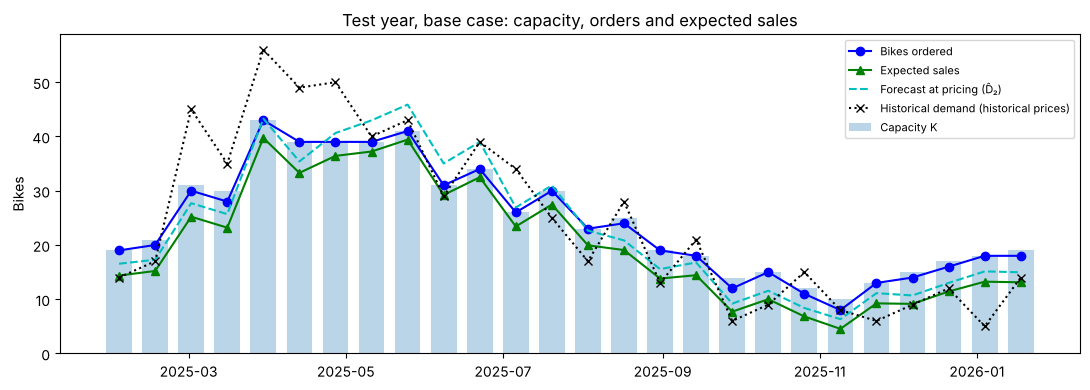

In [23]:
x = pd.to_datetime(plan["period_start"])
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x, plan["capacity_K"], width=10, alpha=0.3, label="Capacity K")
ax.plot(x, plan[["qty_CM", "qty_TT", "qty_UM"]].sum(axis=1), "b-o", label="Bikes ordered")
ax.plot(x, plan["exp_sales"], "g-^", label="Expected sales")
ax.plot(x, plan["forecast_lag2"], "c--", label="Forecast at pricing (D̂₂)")
ax.plot(x, plan["historical_demand"], "k:x", label="Historical demand (historical prices)")
ax.set_title("Test year, base case: capacity, orders and expected sales")
ax.set_ylabel("Bikes")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig_q3_plan.png", dpi=150)
plt.show()

### One-way sensitivity analysis
Each row changes one assumption and keeps the others at the base case, so
interactions between assumptions are not covered.

In [24]:
SCENARIOS = [("base", {})]
SCENARIOS += [(f"cost {int(r * 100)}% of ref. price", {"cost_ratio": r}) for r in (0.60, 0.70, 0.75)]
SCENARIOS += [(f"deposit ${d:.0f}", {"deposit": d}) for d in (50.0, 200.0, 300.0)]
SCENARIOS += [(f"salvage {int(s * 100)}% of cost", {"salvage_ratio": s}) for s in (0.0, 0.25)]
SCENARIOS += [(f"price cap {int(q * 100)}th pct", {"cap_q": q}) for q in (0.90, 0.99)]
SCENARIOS += [("quantity-weighted logit", {"logit": "weighted"})]

sens_rows, sens_plans = [], {}
for name, change in SCENARIOS:
    cfg = {**BASE, **change}
    pl = plan if name == "base" else run_policy(cfg)
    bl = baseline if name == "base" else run_policy({**cfg, "fixed_prices": REF_PRICE})
    sens_plans[name] = pl
    sens_rows.append({**summarize(pl, name), "baseline exp. profit": bl["profit"].sum(),
                      "gain vs baseline": pl["profit"].sum() - bl["profit"].sum()})
sensitivity = pd.DataFrame(sens_rows).set_index("scenario")
sensitivity.round(1)

,capacity K,qty CM,qty TT,qty UM,unused capacity,exp. sales,exp. unsold,binding periods %,CM at cap (periods),TT at cap (periods),UM at cap (periods),avg price CM,exp. revenue,exp. profit,baseline exp. profit,gain vs baseline
scenario,,,,,,,,,,,,,,,,
base,641,541,27,60,13,529.1,98.9,42.3,0,26,26,4568.0,2263675.1,822080.4,232484.9,589595.5
cost 60% of ref. price,665,569,26,55,15,539.4,110.6,42.3,0,26,26,4547.3,2320808.7,936808.4,278563.8,658244.6
cost 70% of ref. price,618,521,27,58,12,519.2,86.8,46.2,0,26,26,4587.3,2217106.4,711880.2,189019.8,522860.4
cost 75% of ref. price,592,489,26,65,12,504.9,75.1,46.2,0,26,26,4611.8,2135895.6,605733.7,147759.6,457974.1
deposit $50,665,544,25,51,45,530.5,89.5,34.6,0,26,26,4566.6,2269489.8,823823.0,232780.4,591042.6
deposit $200,635,545,26,64,0,529.9,105.1,100.0,0,26,26,4564.0,2270173.5,822160.6,232608.3,589552.3
deposit $300,635,545,26,64,0,529.9,105.1,100.0,0,26,26,4564.0,2270173.5,822160.6,232608.3,589552.3
salvage 0% of cost,564,489,8,31,36,483.4,44.6,34.6,0,26,26,4544.7,2112849.5,754064.5,195649.5,558415.0
salvage 25% of cost,594,509,15,36,34,500.6,59.4,38.5,0,26,26,4554.3,2174580.8,780904.4,211059.8,569844.7


In [25]:
plan.to_csv("q3_test_plan.csv", index=False)
baseline.to_csv("q3_baseline_plan.csv", index=False)
comparison.to_csv("q3_comparison.csv")
holdout.to_csv("q3_holdout_check.csv")
grid_check.to_csv("q3_grid_check.csv")
dense_check.to_csv("q3_dense_check.csv", index=False)
k_gap.to_csv("q3_k_gap.csv", header=["value"])
forecast_eval.to_csv("q3_forecast_errors.csv")
estimation_check.to_csv("q3_estimation_check.csv")
plan_fixed.to_csv("q3_fixed_param_plan.csv", index=False)
q2_oos.to_csv("q2_oos_logit.csv", header=["value"])
sensitivity.to_csv("q3_sensitivity.csv")
q1_summary.to_csv("q1_ols_summary.csv", index=False)
validation.to_csv("q1_validation.csv")
q2_table.to_csv("q2_choice_probabilities.csv")
units.to_csv("q2_unit_check.csv")